# PCA and K-means from Scratch
Adapted from undergraduate data-analysis coursework (TP2 and TP3), Paris-Dauphine–PSL.

NumPy implementations of PCA and Lloyd K-means applied to 28 × 28 clothing images.
All code cells were executed successfully in the supplied notebook (Python 3.14.7).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pca import MyPCA
from kmeans import MyKMeans

DATA = Path('data')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
SEED = 42
STANDARDIZE = False


## Dataset overview
Keep the original row order in both CSV files. Labels are used only for evaluation
and visualization, never for fitting PCA or K-means. The original source and class
names remain to be confirmed; numeric labels are displayed without guessing names.


In [2]:
pixels = pd.read_csv(DATA / 'pixels.csv')
labels = pd.read_csv(DATA / 'labels.csv')
X = pixels.to_numpy(dtype=float)
y = labels['label'].to_numpy()
assert X.ndim == 2 and X.shape[1] == 784, 'Expected 784 pixel columns.'
assert len(X) == len(y), 'Pixel and label row counts differ.'
assert len(X) >= 3 and np.isfinite(X).all(), 'Invalid pixel data.'
assert not pd.isna(y).any(), 'Missing labels.'
print('Data shape:', X.shape)
print('Pixel range:', X.min(), X.max())
print(pd.Series(y).value_counts().sort_index())


Data shape: (2535, 784)
Pixel range: 0.0 255.0
0    785
1    863
3    887
Name: count, dtype: int64


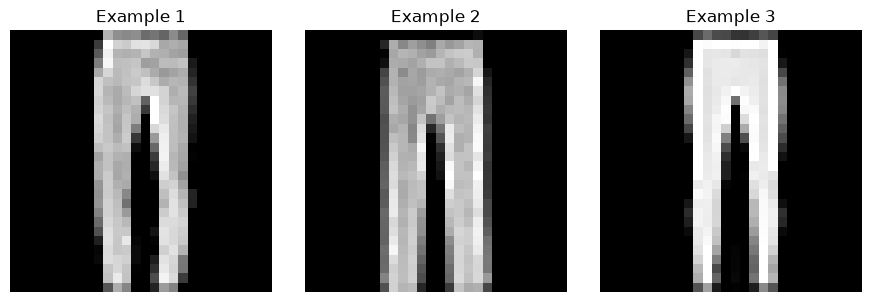

In [3]:
def show_images(images, titles, filename):
    images = np.atleast_2d(images)
    fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 3), squeeze=False)
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image.reshape(28, 28), cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(RESULTS / filename, dpi=150, bbox_inches='tight')
    plt.show()

show_images(X[:3], ['Example 1', 'Example 2', 'Example 3'], 'examples.png')


## PCA: explained variance and reconstruction
Pixels share a common unit. The main experiment uses centered, unscaled pixels.
Set `STANDARDIZE=True` and rerun all cells to explore the alternative; do not mix
outputs from different settings. Component order is descending by eigenvalue.


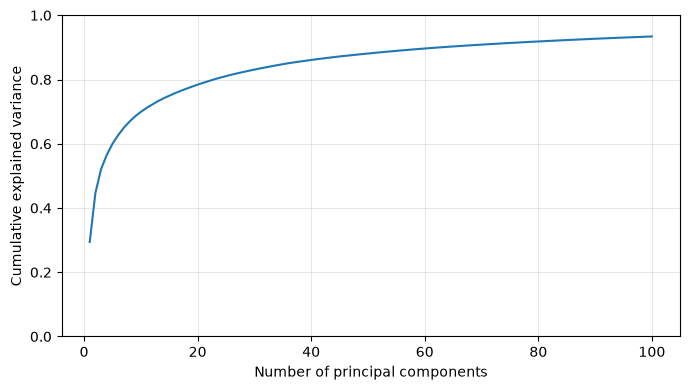

In [4]:
n_components = min(100, X.shape[1], len(X) - 1)
pca = MyPCA(n_components, standardize=STANDARDIZE).fit(X)
Z = pca.transform(X)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, n_components + 1), np.cumsum(pca.explained_variance_ratio))
ax.set(xlabel='Number of principal components', ylabel='Cumulative explained variance', ylim=(0, 1))
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS / 'explained_variance.png', dpi=150)
plt.show()


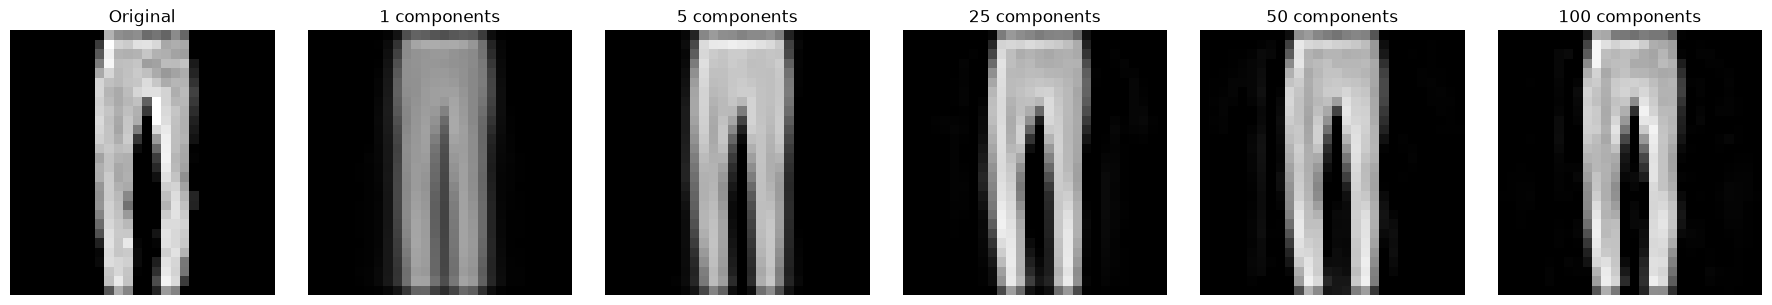

In [5]:
component_counts = [k for k in [1, 5, 25, 50, 100] if k <= n_components]
images = [X[0]]
for k in component_counts:
    partial = Z[:1].copy()
    partial[:, k:] = 0
    images.append(pca.inverse_transform(partial)[0])
show_images(images, ['Original'] + [f'{k} components' for k in component_counts], 'reconstruction.png')


## Clustering before and after PCA
We compare the original pixel space with a few PCA dimensions, always using three
clusters and a fixed random seed. One initialization per setting keeps this
coursework experiment short; it does not establish robust performance differences.

**Cluster purity** is the sum of the largest class count in each cluster divided
by the sample count. It is invariant to cluster numbering, but can be favored by
using more clusters. It is not held-out classification accuracy.


In [6]:
def cluster_purity(true_labels, cluster_labels):
    table = pd.crosstab(np.asarray(cluster_labels), np.asarray(true_labels))
    return table.max(axis=1).sum() / table.to_numpy().sum()

raw_model = MyKMeans(3, random_state=SEED).fit(X)
rows = [{'representation': 'Original pixels', 'dimensions': X.shape[1],
         'purity': cluster_purity(y, raw_model.labels),
         'iterations': raw_model.n_iter, 'converged': raw_model.converged}]
models = {}
for k in sorted(set([min(2, n_components), min(25, n_components), min(50, n_components)])):
    model = MyKMeans(3, random_state=SEED).fit(Z[:, :k])
    models[k] = model
    rows.append({'representation': f'PCA {k}', 'dimensions': k,
                 'purity': cluster_purity(y, model.labels),
                 'iterations': model.n_iter, 'converged': model.converged})
metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS / 'metrics.csv', index=False)
metrics


,representation,dimensions,purity,iterations,converged
0,Original pixels,784,0.568836,35,True
1,PCA 2,2,0.567653,28,True
2,PCA 25,25,0.569231,35,True
3,PCA 50,50,0.568836,34,True


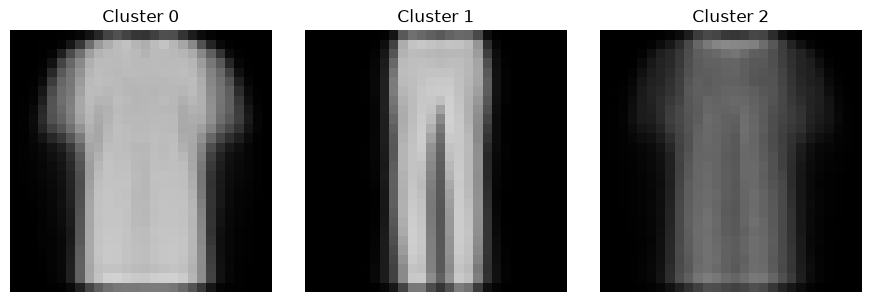

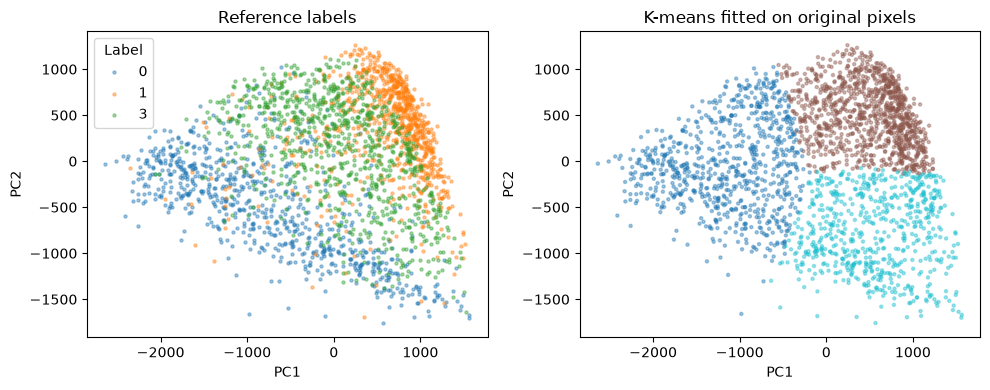

In [7]:
show_images(raw_model.centroids, [f'Cluster {i}' for i in range(3)], 'centroids.png')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label in np.unique(y):
    mask = y == label
    axes[0].scatter(Z[mask, 0], Z[mask, 1], s=5, alpha=0.4, label=str(label))
axes[0].set_title('Reference labels')
axes[0].legend(title='Label')
axes[1].scatter(Z[:, 0], Z[:, 1], c=raw_model.labels, s=5, alpha=0.4, cmap='tab10')
axes[1].set_title('K-means fitted on original pixels')
for ax in axes:
    ax.set(xlabel='PC1', ylabel='PC2')
fig.tight_layout()
fig.savefig(RESULTS / 'projection.png', dpi=150)
plt.show()


## Discussion and limitations
The dataset contains 2,535 images, each represented by 784 pixels with values from
0 to 255. Labels 0, 1 and 3 contain 785, 863 and 887 images respectively.

In this run, K-means purity is 56.88% on original pixels, 56.77% with 2 PCA
components, 56.92% with 25 components and 56.88% with 50 components. All four
runs meet the centroid-movement stopping criterion. The 25-component result is
only 0.04 percentage points above the original-space result; this is not evidence
of a robust improvement. A single initialization is used per setting.

The saved variance plot indicates that 100 components capture approximately 93%
of total variance (visual reading). The displayed example reconstruction becomes
more detailed as more leading components are retained. This single image is an
illustration, not a dataset-wide reconstruction benchmark.

The 2D projection shows overlap between reference labels. Clustering original
pixels recovers some broad regions, but does not cleanly recover the categories.
The right-hand plot shows clusters fitted on all 784 pixels, displayed in PCA 2D.

- This is unsupervised exploratory coursework, not a deployed classifier.
- Purity describes fitted data, not held-out classification accuracy.
- The data source and subset provenance still need documentation.
- Timing has not been benchmarked; fewer dimensions alone do not prove a measured speedup.

## Changes from the submitted coursework
Classes replace progressive monkey-patching; pixel arithmetic uses floats;
components are sorted in descending order; purity is explicitly named; random
initialization is reproducible; empty clusters are handled; labels are recomputed
after the final centroid update. Distance assignment is batched to limit memory.
The original algorithmic scope is retained, with fewer experiment settings.

These are assisted post-coursework corrections and organization changes. The
original teaching scaffold and helper functions are not claimed as wholly original
work. The exact division between student-written code and supplied helpers is not documented here.
